# Larger-scene tiling: engineering demonstration

The ONNX model accepts 512×512. Halo 64 reads a context margin and retains 384×384 cores. Each output pixel is written once, including partial edge tiles. Halo 0 uses non-overlapping 512px cores. Padding outside the image and invalid inputs uses the normalised mean; output no-data comes from the source masks and finite input checks.

This fixture repeats and crops one known validation chip into 800×777 pixels, with an artificial missing-data square. Its coordinates are inherited for an engineering check; they do not represent a real larger observed footprint. Boundary differences show context sensitivity, not proven seam reduction or accuracy improvement. Real-scene validation and Nigeria-specific evaluation remain pending.

Prediction streams individual input windows and output cores. The plotting fixture uses full arrays only because it is small. The tool is memory-bounded with respect to scene size, excluding raster-driver caches and ONNX working memory.

In [1]:
import os
import sys
from pathlib import Path

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT))
# Set SEN1FLOODS11_ROOT to use a different local dataset location.
root = Path(os.environ.get("SEN1FLOODS11_ROOT", str(Path.home() / ".cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11")))
assert (root / "splits/flood_test_data.csv").is_file(), f"Dataset not found: {root}"
print("Dataset:", root)


Dataset: /Users/mac/.cache/kagglehub/datasets/okimosadi/sen1floods11-handlabeled/versions/1/sen1floods11


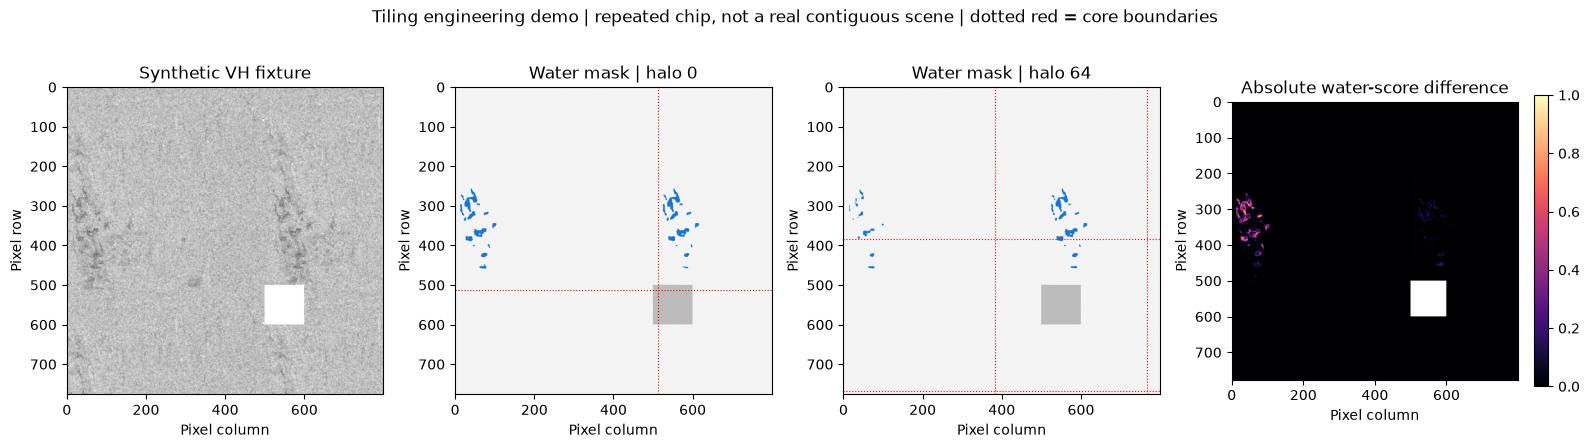

{
  "fixture": "Synthetic repeated/cropped Mekong validation chip; not a real larger scene",
  "width": 800,
  "height": 777,
  "missing_pixels": 10000,
  "mask_disagreements": 1717,
  "mean_abs_score_difference": 0.0033397822757419066,
  "max_abs_score_difference": 0.8294352293014526,
  "interpretation": "Context choices change predictions; no ground-truth accuracy claim"
}
0 {'input': '/Users/mac/Documents/Ml PROJECTS/Flood-Risk-Mapper/reports/m1-s1-kaggle-365653491/tiling_demo/synthetic_scene.tif', 'input_sha256': '0b008d9e743435329f1176c0f0cec76b22ce36ab82fd28106dc86ff9a11b329e', 'model_sha256': '73fb31bbf88120a8f1e1cee20fd7c8b7f78add716a1954afaaa213f1e5bcdb08', 'config_sha256': '20004b9d9c766572eb0adddf0b30fd1323c9326bf058494a6d236e58bfba208e', 'width': 800, 'height': 777, 'crs': 'EPSG:4326', 'transform': [8.983152841195215e-05, 0.0, 105.96958282810253, 0.0, -8.983152841195215e-05, 12.096354289839828, 0.0, 0.0, 1.0], 'threshold': 0.55, 'halo': 0, 'core_size': 512, 'vv_band': 1, 'v

In [2]:
import json
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from floodrisk.deploy.tiled import predict_scene

out = PROJECT / "reports/m1-s1-kaggle-365653491/tiling_demo"
out.mkdir(exist_ok=True)
export = PROJECT / "reports/m1-s1-kaggle-365653491/onnx_fp32"
source = out / "synthetic_scene.tif"
# Repeat and crop a validation chip to exercise partial edge tiles.
# This is an engineering fixture, NOT a real contiguous satellite scene.
if not source.exists():
    with rasterio.open(root / "S1Hand/Mekong_1413877_S1Hand.tif") as src:
        raw = np.tile(src.read(), (1,2,2))[:, :777, :800]
        profile = src.profile.copy()
    raw[:,500:600,500:600] = np.nan
    profile.update(height=777,width=800,dtype="float32",nodata=np.nan,compress="deflate")
    with rasterio.open(source,"w",**profile) as dst: dst.write(raw)
for halo in [0,64]:
    destination = out / f"halo_{halo}"
    if not destination.exists():
        predict_scene(source,export / "m1_s1_fp32.onnx",export / "inference_config.json",destination,halo=halo)
with rasterio.open(source) as src:
    radar=src.read(2,masked=True)
    transform,crs,shape=src.transform,src.crs,src.shape
scores={}
masks={}
for halo in [0,64]:
    with rasterio.open(out / f"halo_{halo}/water_score.tif") as src:
        assert src.transform==transform and src.crs==crs and src.shape==shape
        scores[halo]=src.read(1,masked=True)
    with rasterio.open(out / f"halo_{halo}/water_mask.tif") as src: masks[halo]=src.read(1,masked=True)
valid=~np.ma.getmaskarray(scores[0])
assert np.array_equal(valid,~np.ma.getmaskarray(scores[64]))
difference=np.ma.abs(scores[0]-scores[64])
comparison=dict(fixture="Synthetic repeated/cropped Mekong validation chip; not a real larger scene",
    width=800,height=777,missing_pixels=int((~valid).sum()),
    mask_disagreements=int(((masks[0].data!=masks[64].data)&valid).sum()),
    mean_abs_score_difference=float(difference.mean()),max_abs_score_difference=float(difference.max()),
    interpretation="Context choices change predictions; no ground-truth accuracy claim")
(out / "comparison.json").write_text(json.dumps(comparison,indent=2)+"\n")
fig,axes=plt.subplots(1,4,figsize=(16,4.5))
axes[0].imshow(radar,cmap="gray",vmin=-42,vmax=-5);axes[0].set_title("Synthetic VH fixture")
cmap=ListedColormap(["#f4f4f4","#1976d2"]);cmap.set_bad("#bcbcbc")
for ax,halo in zip(axes[1:3],[0,64]):
    ax.imshow(masks[halo],cmap=cmap,vmin=0,vmax=1);ax.set_title(f"Water mask | halo {halo}")
    core=512-2*halo
    for x in range(core,800,core):ax.axvline(x-0.5,color="red",linestyle=":",linewidth=0.8)
    for y in range(core,777,core):ax.axhline(y-0.5,color="red",linestyle=":",linewidth=0.8)
img=axes[3].imshow(difference,cmap="magma",vmin=0,vmax=1)
axes[3].set_title("Absolute water-score difference")
fig.colorbar(img,ax=axes[3],fraction=0.046)
for ax in axes: ax.set_xlabel("Pixel column");ax.set_ylabel("Pixel row")
fig.suptitle("Tiling engineering demo | repeated chip, not a real contiguous scene | dotted red = core boundaries")
fig.tight_layout();fig.savefig(out / "tiling_comparison.png",dpi=150,bbox_inches="tight")
plt.show();plt.close(fig)
print(json.dumps(comparison,indent=2))
for halo in [0,64]:print(halo,json.loads((out/f"halo_{halo}/prediction.json").read_text()))
